# Adverderial attacks for class imbalance lending default datasets

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

RANDOM_STATE = 42 #for reproducibility


%matplotlib inline

Loading the accepted lending dataset.

"This dataset contains the full LendingClub data available from their site. There are separate files for accepted and rejected loans. The accepted loans also include the FICO scores, which can only be downloaded when you are signed in to LendingClub and download the data." https://www.kaggle.com/datasets/wordsforthewise/lending-club

In [5]:
df = pd.read_csv("data/accepted.csv", low_memory=False)

## Section 1 exploring the dataset

In [6]:
print(f"Number of Records: {df.shape[0]:,.0f}")
print(f"Number of Features: {df.shape[1]}")

Number of Records: 130,583
Number of Features: 151


In [7]:
df.loan_status.value_counts()

loan_status
Fully Paid            92097
Charged Off           22852
Current               14760
Late (31-120 days)      536
In Grace Period         235
Late (16-30 days)       102
Default                   1
Name: count, dtype: int64

For this research we only care about paid off and defaulted a.k.a charged off

In [8]:
df = df[df.loan_status.isin(['Fully Paid', 'Charged Off'])]

In [9]:
print("Columns:")
for col in df.columns:
    print(f" - {col}")

Columns:
 - id
 - member_id
 - loan_amnt
 - funded_amnt
 - funded_amnt_inv
 - term
 - int_rate
 - installment
 - grade
 - sub_grade
 - emp_title
 - emp_length
 - home_ownership
 - annual_inc
 - verification_status
 - issue_d
 - loan_status
 - pymnt_plan
 - url
 - desc
 - purpose
 - title
 - zip_code
 - addr_state
 - dti
 - delinq_2yrs
 - earliest_cr_line
 - fico_range_low
 - fico_range_high
 - inq_last_6mths
 - mths_since_last_delinq
 - mths_since_last_record
 - open_acc
 - pub_rec
 - revol_bal
 - revol_util
 - total_acc
 - initial_list_status
 - out_prncp
 - out_prncp_inv
 - total_pymnt
 - total_pymnt_inv
 - total_rec_prncp
 - total_rec_int
 - total_rec_late_fee
 - recoveries
 - collection_recovery_fee
 - last_pymnt_d
 - last_pymnt_amnt
 - next_pymnt_d
 - last_credit_pull_d
 - last_fico_range_high
 - last_fico_range_low
 - collections_12_mths_ex_med
 - mths_since_last_major_derog
 - policy_code
 - application_type
 - annual_inc_joint
 - dti_joint
 - verification_status_joint
 - acc_no

In [10]:
df.head()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,68407277,NaN,3600.0,3600.0,3600.0,36 months,13.99,123.03,C,C4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,68355089,NaN,24700.0,24700.0,24700.0,36 months,11.99,820.28,C,C1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,68341763,NaN,20000.0,20000.0,20000.0,60 months,10.78,432.66,B,B4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
4,68476807,NaN,10400.0,10400.0,10400.0,60 months,22.45,289.91,F,F1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
5,68426831,NaN,11950.0,11950.0,11950.0,36 months,13.44,405.18,C,C3,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
missing = df.isnull().sum()
missing

id                            0
member_id                114949
loan_amnt                     0
funded_amnt                   0
funded_amnt_inv               0
                          ...  
settlement_status        111144
settlement_date          111144
settlement_amount        111144
settlement_percentage    111144
settlement_term          111144
Length: 151, dtype: int64

We see a lot of nan values so lets drop the features that have a lot of NaN values

In [12]:
missing_percent = (missing / len(df)) * 100

missing_table = pd.DataFrame({
    'Missing Values': missing,
    'Percentage (%)': missing_percent
})

missing_table = missing_table.sort_values(by='Percentage (%)', ascending=False)
pd.set_option('display.max_rows', None)

missing_table

,Missing Values,Percentage (%)
revol_bal_joint,114949,100.000000
sec_app_inq_last_6mths,114949,100.000000
sec_app_earliest_cr_line,114949,100.000000
sec_app_fico_range_high,114949,100.000000
sec_app_num_rev_accts,114949,100.000000
sec_app_chargeoff_within_12_mths,114949,100.000000
sec_app_collections_12_mths_ex_med,114949,100.000000
sec_app_mths_since_last_major_derog,114949,100.000000
sec_app_mort_acc,114949,100.000000
sec_app_open_act_il,114949,100.000000


In [13]:
cols_to_drop = missing_table[missing_table['Percentage (%)'] > 50].index # Selects columsn with > 50% missing and returns their names

print("Columns to drop:")
for col in cols_to_drop:
    print(f" - {col}")

df = df.drop(columns=cols_to_drop, errors='ignore')

Columns to drop:
 - revol_bal_joint
 - sec_app_inq_last_6mths
 - sec_app_earliest_cr_line
 - sec_app_fico_range_high
 - sec_app_num_rev_accts
 - sec_app_chargeoff_within_12_mths
 - sec_app_collections_12_mths_ex_med
 - sec_app_mths_since_last_major_derog
 - sec_app_mort_acc
 - sec_app_open_act_il
 - sec_app_revol_util
 - member_id
 - next_pymnt_d
 - sec_app_open_acc
 - sec_app_fico_range_low
 - desc
 - dti_joint
 - verification_status_joint
 - annual_inc_joint
 - orig_projected_additional_accrued_interest
 - hardship_end_date
 - hardship_payoff_balance_amount
 - payment_plan_start_date
 - hardship_length
 - deferral_term
 - hardship_amount
 - hardship_reason
 - hardship_type
 - hardship_dpd
 - hardship_start_date
 - hardship_status
 - hardship_loan_status
 - hardship_last_payment_amount
 - settlement_term
 - settlement_percentage
 - settlement_amount
 - settlement_status
 - debt_settlement_flag_date
 - settlement_date
 - il_util
 - mths_since_rcnt_il
 - all_util
 - total_cu_tl
 - inq_f

In [14]:
df.shape

(114949, 94)

Following the Kaggle notebooks we will keep the following collumns

| # | Feature | Description |
|---|---------|-------------|
| 0 | `loan_amnt` | The listed amount of the loan applied for by the borrower. If at some point in time, the credit department reduces the loan amount, then it will be reflected in this value. |
| 1 | `term` | The number of payments on the loan. Values are in months and can be either 36 or 60. |
| 2 | `int_rate` | Interest Rate on the loan |
| 3 | `installment` | The monthly payment owed by the borrower if the loan originates. |
| 4 | `grade` | LC assigned loan grade |
| 5 | `sub_grade` | LC assigned loan subgrade |
| 6 | `emp_length` | Employment length in years. Possible values are between 0 and 10 where 0 means less than one year and 10 means ten or more years. |
| 7 | `home_ownership` | The home ownership status provided by the borrower during registration or obtained from the credit report. Values: RENT, OWN, MORTGAGE, OTHER |
| 8 | `annual_inc` | The self-reported annual income provided by the borrower during registration. |
| 9 | `verification_status` | Indicates if income was verified by LC, not verified, or if the income source was verified |
| 10 | `issue_d` | The month which the loan was funded |
| 11 | `loan_status` | Current status of the loan |
| 12 | `purpose` | A category provided by the borrower for the loan request. |
| 13 | `title` | The loan title provided by the borrower |
| 14 | `zip_code` | The first 3 numbers of the zip code provided by the borrower in the loan application. |
| 15 | `addr_state` | The state provided by the borrower in the loan application |
| 16 | `dti` | A ratio calculated using the borrower's total monthly debt payments on the total debt obligations, excluding mortgage and the requested LC loan, divided by the borrower's self-reported monthly income. |
| 17 | `earliest_cr_line` | The month the borrower's earliest reported credit line was opened |
| 18 | `open_acc` | The number of open credit lines in the borrower's credit file. |
| 19 | `pub_rec` | Number of derogatory public records |
| 20 | `revol_bal` | Total credit revolving balance |
| 21 | `revol_util` | Revolving line utilization rate, or the amount of credit the borrower is using relative to all available revolving credit. |
| 22 | `total_acc` | The total number of credit lines currently in the borrower's credit file |
| 23 | `initial_list_status` | The initial listing status of the loan. Possible values are W, F |
| 24 | `application_type` | Indicates whether the loan is an individual application or a joint application with two co-borrowers |
| 25 | `mort_acc` | Number of mortgage accounts. |
| 26 | `pub_rec_bankruptcies` | Number of public record bankruptcies. |

In [15]:
df = df[[
    'loan_amnt', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_length',
    'home_ownership', 'annual_inc', 'verification_status', 'issue_d',
    'loan_status', 'purpose', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line',
    'fico_range_low', 'fico_range_high', 'inq_last_6mths', 'open_acc',
    'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status',
    'application_type', 'mort_acc', 'pub_rec_bankruptcies'
]]

In [16]:
df.describe()

,loan_amnt,int_rate,installment,annual_inc,dti,delinq_2yrs,fico_range_low,fico_range_high,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc,mort_acc,pub_rec_bankruptcies
count,114949.000000,114949.000000,114949.000000,1.149490e+05,114947.000000,114949.000000,114949.000000,114949.000000,114949.000000,114949.000000,114949.000000,114949.000000,114907.000000,114949.000000,114948.000000,114948.000000
mean,14440.064072,11.995763,431.981726,7.788240e+04,19.011872,0.350555,694.407346,698.407476,0.595012,11.885523,0.243821,17189.540387,51.847345,25.231163,1.648920,0.138236
std,8593.911916,4.160739,253.844657,8.920632e+04,9.466697,0.928153,31.003525,31.004161,0.883935,5.659595,0.704502,23709.305472,24.059179,12.135841,1.952167,0.391291
min,1000.000000,5.320000,14.770000,0.000000e+00,0.000000,0.000000,660.000000,664.000000,0.000000,1.000000,0.000000,0.000000,0.000000,4.000000,0.000000,0.000000
25%,8000.000000,8.380000,246.730000,4.600000e+04,12.370000,0.000000,670.000000,674.000000,0.000000,8.000000,0.000000,6077.000000,33.800000,16.000000,0.000000,0.000000
50%,12000.000000,11.530000,371.960000,6.500000e+04,18.440000,0.000000,685.000000,689.000000,0.000000,11.000000,0.000000,11355.000000,51.600000,24.000000,1.000000,0.000000
75%,20000.000000,14.330000,573.830000,9.270000e+04,25.220000,0.000000,710.000000,714.000000,1.000000,15.000000,0.000000,20519.000000,70.100000,32.000000,3.000000,0.000000
max,35000.000000,28.990000,1445.460000,9.000000e+06,999.000000,30.000000,845.000000,850.000000,5.000000,67.000000,86.000000,898146.000000,182.800000,151.000000,35.000000,8.000000


In [17]:
df.dtypes

loan_amnt               float64
term                     object
int_rate                float64
installment             float64
grade                    object
sub_grade                object
emp_length               object
home_ownership           object
annual_inc              float64
verification_status      object
issue_d                  object
loan_status              object
purpose                  object
addr_state               object
dti                     float64
delinq_2yrs             float64
earliest_cr_line         object
fico_range_low          float64
fico_range_high         float64
inq_last_6mths          float64
open_acc                float64
pub_rec                 float64
revol_bal               float64
revol_util              float64
total_acc               float64
initial_list_status      object
application_type         object
mort_acc                float64
pub_rec_bankruptcies    float64
dtype: object

We Want to predict the rate of default so we wil rename it to target

In [18]:
df = df.rename(columns={"loan_status": "target"})
df["target"] = df["target"].map({"Charged Off": 1, "Fully Paid": 0})


# Visualisation of the dataset

In [19]:
df.groupby("target").count()

,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,...,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,application_type,mort_acc,pub_rec_bankruptcies
target,,,,,,,,,,,,,,,,,,,,,
0,92097,92097,92097,92097,92097,92097,86541,92097,92097,92097,...,92097,92097,92097,92097,92066,92097,92097,92096,92096,92096
1,22852,22852,22852,22852,22852,22852,21010,22852,22852,22852,...,22852,22852,22852,22852,22841,22852,22852,22852,22852,22852


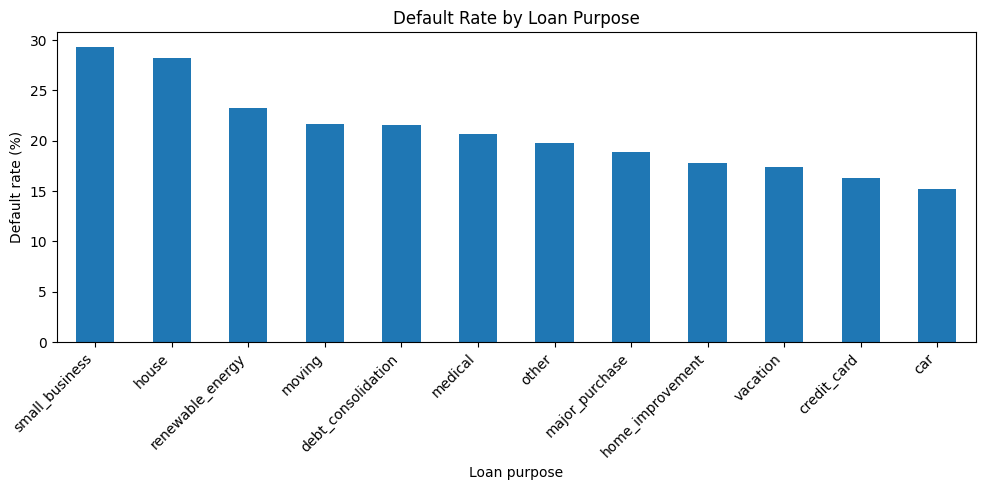

In [20]:
purpose_default_rate = (
    df.groupby("purpose")["target"].mean().sort_values(ascending=False) * 100
)

plt.figure(figsize=(10, 5))
purpose_default_rate.plot(kind="bar")

plt.title("Default Rate by Loan Purpose")
plt.xlabel("Loan purpose")
plt.ylabel("Default rate (%)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

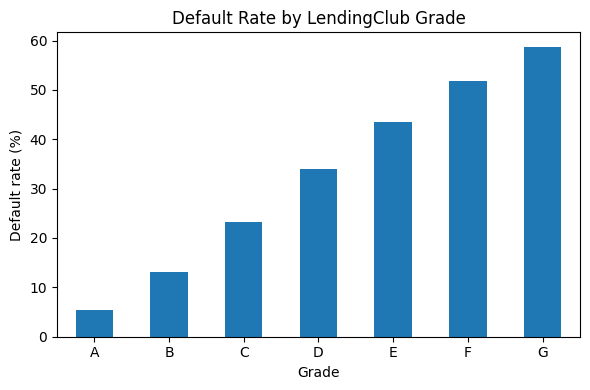

In [21]:
grade_default_rate = (
    df
    .groupby("grade")["target"]
    .mean()
    .sort_index() * 100
)

plt.figure(figsize=(6, 4))
grade_default_rate.plot(kind="bar")

plt.title("Default Rate by LendingClub Grade")
plt.xlabel("Grade")
plt.ylabel("Default rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

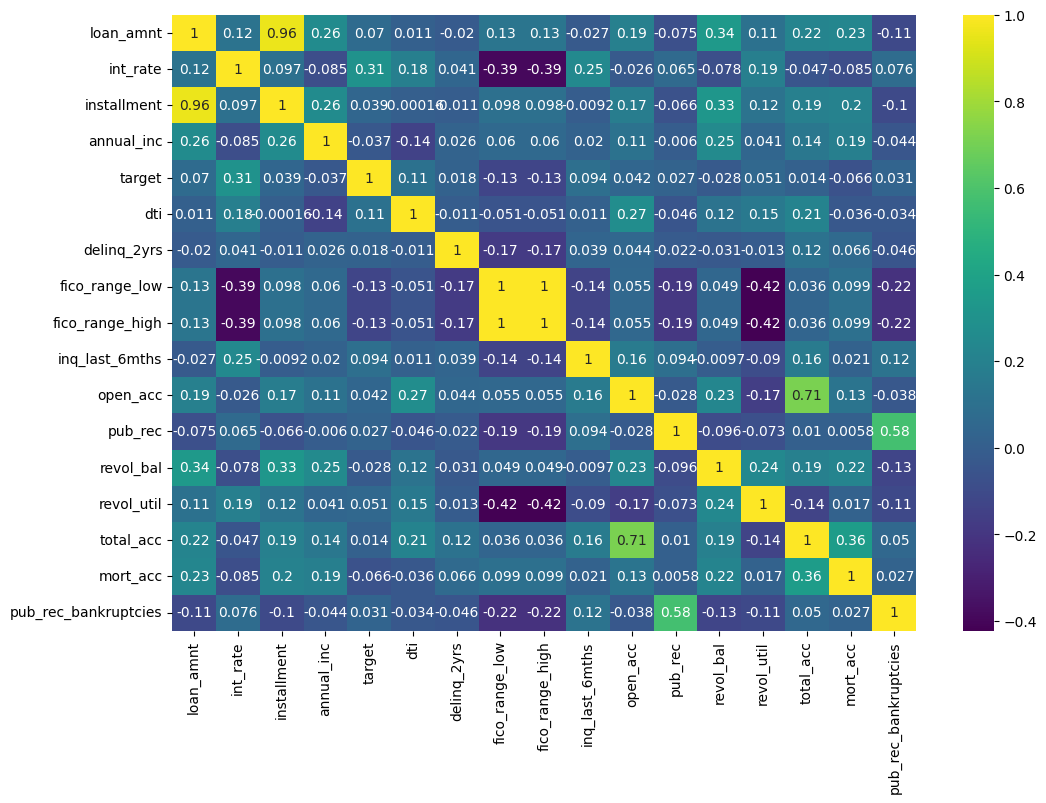

In [22]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='viridis')
plt.show()

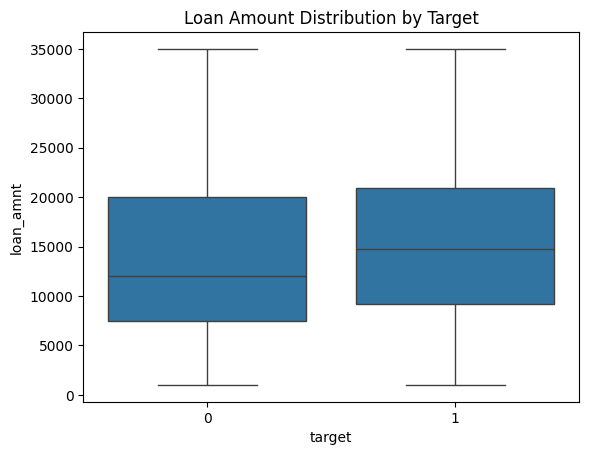

In [23]:
boxplot = sns.boxplot(x="target", y="loan_amnt", data=df)
boxplot.set_title("Loan Amount Distribution by Target")
plt.show()

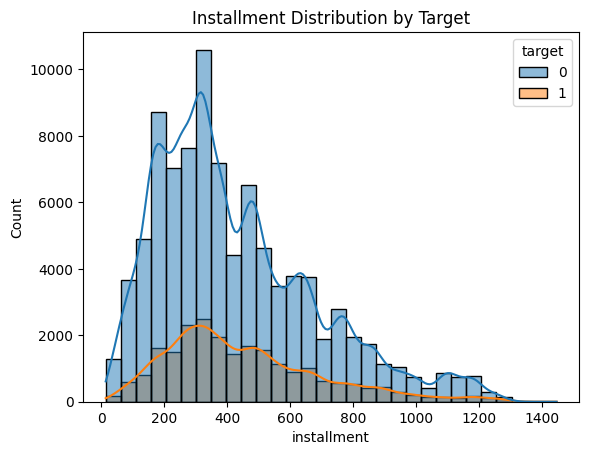

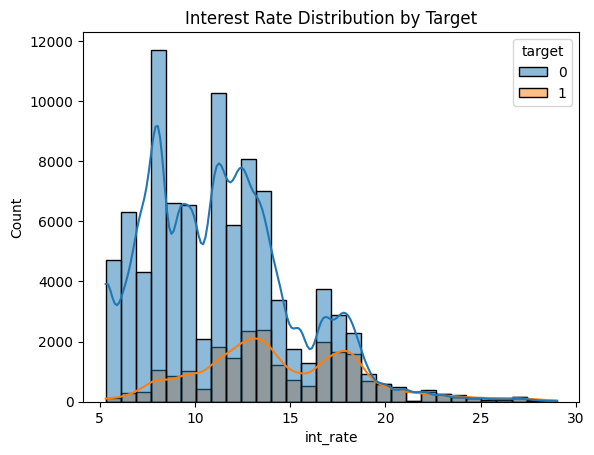

In [24]:
installment = sns.histplot(data=df, x="installment", hue="target", kde=True, bins=30)
installment.set_title("Installment Distribution by Target")

plt.show()

interest_rate = sns.histplot(data=df, x="int_rate", hue="target", kde=True, bins=30)
interest_rate.set_title("Interest Rate Distribution by Target")

plt.show()

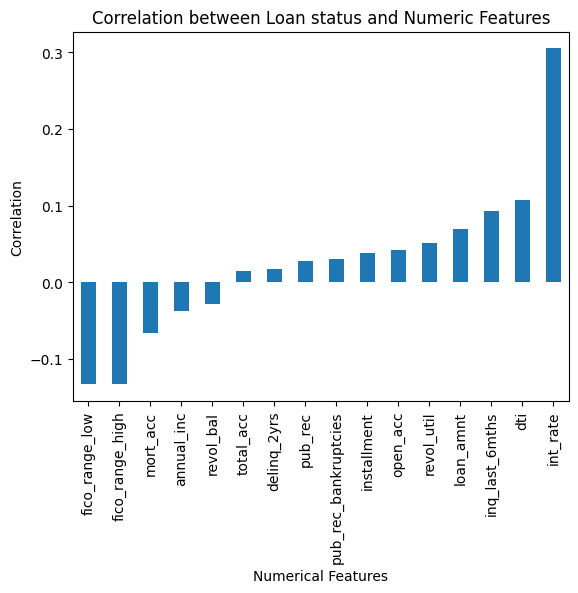

In [25]:
df.corr(numeric_only=True)['target'].drop('target').sort_values().plot(kind='bar',
    title="Correlation between Loan status and Numeric Features", 
    ylabel='Correlation', xlabel='Numerical Features', 
)
plt.show()

# Section 2 DPT

### Convert categorical features into numereric

In [26]:
df.dtypes

loan_amnt               float64
term                     object
int_rate                float64
installment             float64
grade                    object
sub_grade                object
emp_length               object
home_ownership           object
annual_inc              float64
verification_status      object
issue_d                  object
target                    int64
purpose                  object
addr_state               object
dti                     float64
delinq_2yrs             float64
earliest_cr_line         object
fico_range_low          float64
fico_range_high         float64
inq_last_6mths          float64
open_acc                float64
pub_rec                 float64
revol_bal               float64
revol_util              float64
total_acc               float64
initial_list_status      object
application_type         object
mort_acc                float64
pub_rec_bankruptcies    float64
dtype: object

In [27]:
df.application_type.unique()

array(['Individual', 'Joint App', nan], dtype=object)

Since application type is just two values we binary encode

In [28]:
df['Individual application'] = df['application_type'] == 'INDIVIDUAL'
df.drop(columns=['application_type'], inplace=True)

In [29]:
df.emp_length.unique()

array(['10+ years', '3 years', '4 years', '6 years', '7 years', '8 years',
       '2 years', '5 years', '9 years', '< 1 year', '1 year', nan],
      dtype=object)

employement length we can ordinal encode

In [30]:
df["emp_length"] = df["emp_length"].map({"< 1 year": 0, "1 year": 1, "2 years": 2, "3 years": 3, "4 years": 4, "5 years": 5, "6 years": 6, "7 years": 7, "8 years": 8, "9 years": 9, "10+ years": 10})

In [31]:
df.term.value_counts()

term
36 months    88689
60 months    26260
Name: count, dtype: int64

For term we kan strip the months and convert to int

In [32]:
df["term"].fillna("36 months", inplace=True)

/tmp/ipykernel_474/2803924516.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["term"].fillna("36 months", inplace=True)


In [33]:
df["term"] = df["term"].str.strip().str.replace(" months", "").astype(int)

In [34]:
df.purpose.value_counts().head()

purpose
debt_consolidation    65188
credit_card           28829
home_improvement       7378
other                  6162
major_purchase         2273
Name: count, dtype: int64

In [35]:
df['verification_status'].value_counts()

verification_status
Source Verified    49341
Verified           37077
Not Verified       28531
Name: count, dtype: int64

In [36]:
df['initial_list_status'].value_counts()

initial_list_status
w    85280
f    29669
Name: count, dtype: int64

In [37]:
df['home_ownership'].value_counts()

home_ownership
MORTGAGE    56246
RENT        45684
OWN         13018
ANY             1
Name: count, dtype: int64

We also know subgrade is a more detailed version of grade, so we can drop grade.

In [38]:
df.drop('grade', axis=1, inplace=True)

dummies = ['sub_grade', 'verification_status', 'purpose', 'initial_list_status', 'home_ownership', 'addr_state']
df = pd.get_dummies(df, columns=dummies, drop_first=True)



In [39]:
df.dtypes == "object"

loan_amnt                              False
term                                   False
int_rate                               False
installment                            False
emp_length                             False
annual_inc                             False
issue_d                                 True
target                                 False
dti                                    False
delinq_2yrs                            False
earliest_cr_line                        True
fico_range_low                         False
fico_range_high                        False
inq_last_6mths                         False
open_acc                               False
pub_rec                                False
revol_bal                              False
revol_util                             False
total_acc                              False
mort_acc                               False
pub_rec_bankruptcies                   False
Individual application                 False
sub_grade_

In [40]:
df['earliest_cr_line'].head()

0    Aug-2003
1    Dec-1999
2    Aug-2000
4    Jun-1998
5    Oct-1987
Name: earliest_cr_line, dtype: object

In [41]:
df["earliest_cr_line"] = pd.to_datetime(df["earliest_cr_line"], format="%b-%Y")

# Credit history length in years, relative to a fixed reference (dataset ~2018)
reference = pd.Timestamp("2018-01-01")
df["credit_history_yrs"] = (reference - df["earliest_cr_line"]).dt.days / 365.25

df.drop(columns="earliest_cr_line", inplace=True)

We need to drop issue date since it is data leakage as the model would no know if the loan has been approved or not before making its prediction

In [42]:
df.drop('issue_d', axis=1, inplace=True)



## Fill missing values

In [43]:
df.isnull().sum()

loan_amnt                                 0
term                                      0
int_rate                                  0
installment                               0
emp_length                             7398
annual_inc                                0
target                                    0
dti                                       2
delinq_2yrs                               0
fico_range_low                            0
fico_range_high                           0
inq_last_6mths                            0
open_acc                                  0
pub_rec                                   0
revol_bal                                 0
revol_util                               42
total_acc                                 0
mort_acc                                  1
pub_rec_bankruptcies                      1
Individual application                    0
sub_grade_A2                              0
sub_grade_A3                              0
sub_grade_A4                    

We see that multiple row have 33 null values. Are these the same rows?

In [44]:
df[df['loan_amnt'].isnull() == True].isnull().sum()

loan_amnt                              0
term                                   0
int_rate                               0
installment                            0
emp_length                             0
annual_inc                             0
target                                 0
dti                                    0
delinq_2yrs                            0
fico_range_low                         0
fico_range_high                        0
inq_last_6mths                         0
open_acc                               0
pub_rec                                0
revol_bal                              0
revol_util                             0
total_acc                              0
mort_acc                               0
pub_rec_bankruptcies                   0
Individual application                 0
sub_grade_A2                           0
sub_grade_A3                           0
sub_grade_A4                           0
sub_grade_A5                           0
sub_grade_B1    

Yess these rows contain a lot of null vallues lets drop them

In [45]:
df = df.dropna(subset=['loan_amnt'])

In [46]:
df.isnull().sum()

loan_amnt                                 0
term                                      0
int_rate                                  0
installment                               0
emp_length                             7398
annual_inc                                0
target                                    0
dti                                       2
delinq_2yrs                               0
fico_range_low                            0
fico_range_high                           0
inq_last_6mths                            0
open_acc                                  0
pub_rec                                   0
revol_bal                                 0
revol_util                               42
total_acc                                 0
mort_acc                                  1
pub_rec_bankruptcies                      1
Individual application                    0
sub_grade_A2                              0
sub_grade_A3                              0
sub_grade_A4                    

In [47]:
df = df.dropna(subset=["target"])

Define imputer to fill the rest of the missing values

In [48]:
from sklearn.impute import SimpleImputer


num_cols = df.select_dtypes(include="number").columns.drop("target")
cols_to_impute = num_cols[df[num_cols].isnull().any()].tolist()
print("Numeric columns to impute:", cols_to_impute)

imputer = SimpleImputer(strategy="median")
df[cols_to_impute] = imputer.fit_transform(df[cols_to_impute])

Numeric columns to impute: ['emp_length', 'dti', 'revol_util', 'mort_acc', 'pub_rec_bankruptcies']


### This dataset does not have that much class imbalance. For our research we want class imbalce, so we will randomly undersample to get the minority class to 1%

In [49]:
minority_frac = 0.01

majority = df[df["target"] == 0]
minority = df[df["target"] == 1]

n_minority = int(round(minority_frac / (1 - minority_frac) * len(majority)))

minority_down = minority.sample(n=n_minority, random_state=RANDOM_STATE)

df_imbalanced = (
    pd.concat([majority, minority_down])
    .sample(frac=1, random_state=RANDOM_STATE)
    .reset_index(drop=True)
)

print(df_imbalanced["target"].value_counts())
print(df_imbalanced["target"].value_counts(normalize=True))  # ~0.99 / 0.01


target
0    92097
1      930
Name: count, dtype: int64
target
0    0.990003
1    0.009997
Name: proportion, dtype: float64


Finally split into Test and Train

In [50]:
train_df, test_df = train_test_split(df_imbalanced, test_size=0.2, random_state=RANDOM_STATE)

In [51]:
X_train = train_df.drop(columns="target")
y_train = train_df["target"]
X_test = test_df.drop(columns="target")
y_test = test_df["target"]

# Section 3 resampling

For oversampling we will use:
- Class weighting (cost-sensitive Learning)
- Random Under-Sampling
- SMOTE-ENN (Edited Nearest Neighbour)
- K-Means SMOTE



In [54]:
pip install imbalanced-learn

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [imbalanced-learn][imbalanced-learn]

[notice] A new release of pip is available: 25.3 -> 26.1.2
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [55]:
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTEENN
from imblearn.over_sampling import KMeansSMOTE

In [56]:
random_under_sampler = RandomUnderSampler(sampling_strategy='majority', random_state=RANDOM_STATE)
X_train_undersampled, y_train_undersampled = random_under_sampler.fit_resample(X_train, y_train)

In [57]:
smote_enn = SMOTEENN(sampling_strategy='minority', random_state=RANDOM_STATE)
X_train_smoteenn, y_train_smoteenn = smote_enn.fit_resample(X_train, y_train)

OpenBLAS warning: precompiled NUM_THREADS exceeded, adding auxiliary array for thread metadata.
To avoid this warning, please rebuild your copy of OpenBLAS with a larger NUM_THREADS setting
or set the environment variable OPENBLAS_NUM_THREADS to 64 or lower


: 

: 

: 

In [ ]:
kmeans_smote = KMeansSMOTE(sampling_strategy='minority', random_state=RANDOM_STATE)
X_train_kmeans_smote, y_train_kmeans_smote = kmeans_smote.fit_resample(X_train, y_train)

# Section 4 Model Implementation

We will implement the following models that have surfaced in the literature review:
- Random forest
- Logistic regression
- XGBoost
- Neural Network

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from torch import nn

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score
from time import process_time


In [ ]:
def model(method, x_train, y_train, x_test, y_test):
    # Train the model
    start_time = process_time()
    method.fit(x_train, y_train)
    end_time = process_time()
    print(f"Training time: {end_time - start_time:.2f} seconds")
    
    # Make predictions on test data and calculate confusion matrix
    start_time = process_time()
    predictions = method.predict(x_test)
    end_time = process_time()
    print(f"Prediction time: {end_time - start_time:.2f} seconds")
    c_matrix = confusion_matrix(y_test, predictions)
    
    # Evaluate model performance and print results
    print("ROC AUC: ", '{:.2%}'.format(roc_auc_score(y_test, predictions)))
    print("Model accuracy: ", '{:.2%}'.format(accuracy_score(y_test, predictions)))
    print(classification_report(y_test, predictions))

In [ ]:
gradient_boosting = XGBClassifier(random_state=RANDOM_STATE, use_label_encoder=False, eval_metric='logloss')
model(gradient_boosting, X_train, y_train, X_test, y_test)

In [ ]:
logistic_regression = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)
model(logistic_regression, X_train, y_train, X_test, y_test)

In [ ]:
random_forest = RandomForestClassifier(random_state=RANDOM_STATE)
model(random_forest, X_train, y_train, X_test, y_test)